# 03 – DCF Check, Comparable Companies and Charts

This notebook only uses the CSV files in `../data/`, so it runs without the internet.

1. Rebuild the Base-case DCF in Python (to double-check the Excel model)
2. Reverse DCF: what growth rate is the market pricing in?
3. Comparable Company Analysis (EV/EBITDA and Forward P/E)
4. Charts for the README / Power BI

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

income = pd.read_csv("../data/income_statement.csv")
balance = pd.read_csv("../data/balance_sheet.csv")
cashflow = pd.read_csv("../data/cash_flow.csv")
peers = pd.read_csv("../data/peer_comps.csv")
products = pd.read_csv("../data/revenue_by_product.csv")

## 1. DCF (Base case)

In [2]:
# Historical drivers
growth = income["total_revenue"].pct_change()             # YoY revenue growth
fcf_margin = cashflow["free_cash_flow"] / income["total_revenue"]

avg_growth = growth.mean()        # average of FY2023-FY2026 (first value is NaN and is skipped)
avg_fcf_margin = fcf_margin.mean()
print(f"Average revenue growth: {avg_growth:.2%}")
print(f"Average FCF margin: {avg_fcf_margin:.2%}")

Average revenue growth: 5.18%
Average FCF margin: 26.84%


In [3]:
# Inputs (same as the Excel 'Assumptions' sheet)
wacc_table = pd.read_csv("../data/wacc.csv").set_index("metric")["value"]   # saved by notebook 02
WACC = wacc_table["wacc"]
terminal_growth = 0.025
cash_and_securities = 36305 + 20417 + 80213   # cash + current + non-current marketable securities, FY2026 ($m)
total_debt = 80111                            # commercial paper + term debt, FY2026 ($m)
shares = 14532.182                            # million shares
share_price = 356.27

def dcf_price(growth_rate, wacc=WACC, g=terminal_growth, margin=avg_fcf_margin):
    revenue = income["total_revenue"].iloc[-1]   # FY2026 revenue
    pv_fcf = 0
    for year in range(1, 6):                     # FY2027 - FY2031
        revenue = revenue * (1 + growth_rate)
        fcf = revenue * margin
        pv_fcf = pv_fcf + fcf / (1 + wacc) ** year
    terminal_value = fcf * (1 + g) / (wacc - g)
    pv_terminal = terminal_value / (1 + wacc) ** 5
    enterprise_value = pv_fcf + pv_terminal
    equity_value = enterprise_value - total_debt + cash_and_securities
    return equity_value / shares

dcf_value = dcf_price(avg_growth)
print(f"DCF value per share: ${dcf_value:.2f}  vs price ${share_price}")

DCF value per share: $138.86  vs price $356.27


## 2. Reverse DCF
Instead of asking "what is Apple worth?", ask "what growth does $356 already assume?" — the same idea as **Goal Seek** in Excel.

In [4]:
low, high = 0.0, 0.60
for _ in range(100):                 # simple bisection search
    mid = (low + high) / 2
    if dcf_price(mid) < share_price:
        low = mid
    else:
        high = mid
print(f"Revenue growth needed for 5 years to justify ${share_price}: {mid:.1%} per year")

Revenue growth needed for 5 years to justify $356.27: 30.0% per year


## 3. Comparable Company Analysis

In [5]:
peer_only = peers[peers["ticker"] != "AAPL"]
median_ev_ebitda = (peer_only["enterprise_value_b"] / peer_only["ttm_ebitda_b"]).median()   # EV / EBITDA, same as Excel
median_forward_pe = peer_only["forward_pe"].median()

aapl = peers[peers["ticker"] == "AAPL"].iloc[0]
aapl_forward_eps = aapl["price"] / aapl["forward_pe"]     # consensus next-12-month EPS implied by the quote

# EV/EBITDA method: EV -> Equity -> per share
implied_ev = median_ev_ebitda * aapl["ttm_ebitda_b"] * 1000      # $ millions
price_ev_ebitda = (implied_ev - total_debt + cash_and_securities) / shares

# Forward P/E method
price_pe = median_forward_pe * aapl_forward_eps

print(f"Peer median EV/EBITDA: {median_ev_ebitda:.2f}x -> ${price_ev_ebitda:.2f}")
print(f"Peer median Forward P/E: {median_forward_pe:.2f}x -> ${price_pe:.2f}")
comps_value = (price_ev_ebitda + price_pe) / 2
print(f"Comps value: ${comps_value:.2f}")

Peer median EV/EBITDA: 18.97x -> $227.81
Peer median Forward P/E: 21.45x -> $202.06
Comps value: $214.94


Why not trailing P/E? Alphabet's trailing P/E (15.4x) is pulled down by large one-time investment gains in its net income, so it is not comparable. Forward P/E and EV/EBITDA avoid that problem.

In [6]:
target_price = 0.5 * dcf_value + 0.5 * comps_value
upside = target_price / share_price - 1
if upside > 0.15:
    rating = "BUY"
elif upside < -0.15:
    rating = "SELL"
else:
    rating = "HOLD"
print(f"Target price: ${target_price:.2f} | Upside: {upside:.1%} | Rating: {rating}")

Target price: $176.90 | Upside: -50.3% | Rating: SELL


## 4. Charts

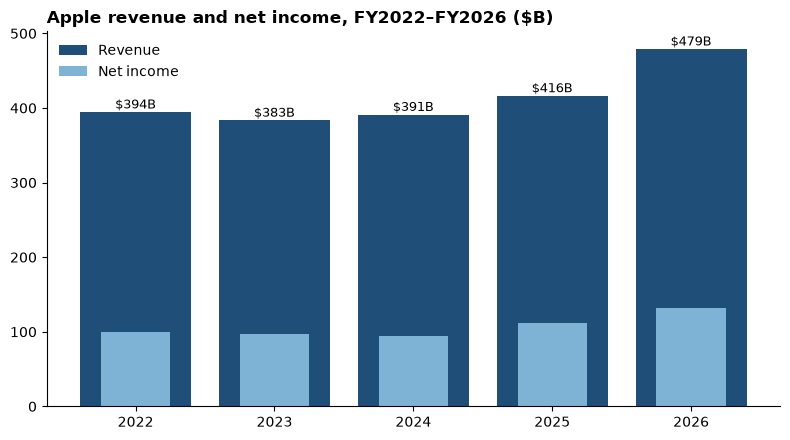

In [7]:
import os
os.makedirs("../images", exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
years = income["fiscal_year"].astype(str)

# Chart 1: Revenue and Net Income
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(years, income["total_revenue"] / 1000, color="#1f4e79", label="Revenue")
ax.bar(years, income["net_income"] / 1000, color="#7fb3d5", label="Net income", width=0.5)
for x, v in zip(years, income["total_revenue"] / 1000):
    ax.text(x, v + 5, f"${v:.0f}B", ha="center", fontsize=9)
ax.set_title("Apple revenue and net income, FY2022–FY2026 ($B)", loc="left", fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("../images/revenue_net_income.png", dpi=150); plt.show()

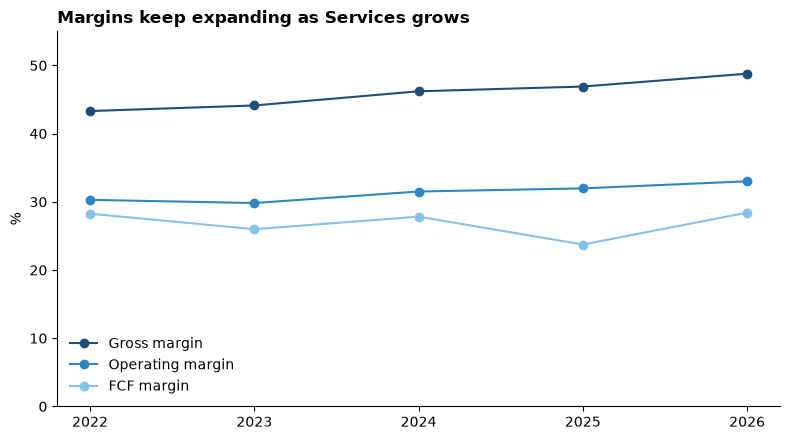

In [8]:
# Chart 2: Margins
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(years, income["gross_profit"] / income["total_revenue"] * 100, marker="o", color="#1f4e79", label="Gross margin")
ax.plot(years, income["operating_income"] / income["total_revenue"] * 100, marker="o", color="#2e86c1", label="Operating margin")
ax.plot(years, fcf_margin * 100, marker="o", color="#85c1e9", label="FCF margin")
ax.set_ylabel("%"); ax.set_ylim(0, 55)
ax.set_title("Margins keep expanding as Services grows", loc="left", fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("../images/margins.png", dpi=150); plt.show()

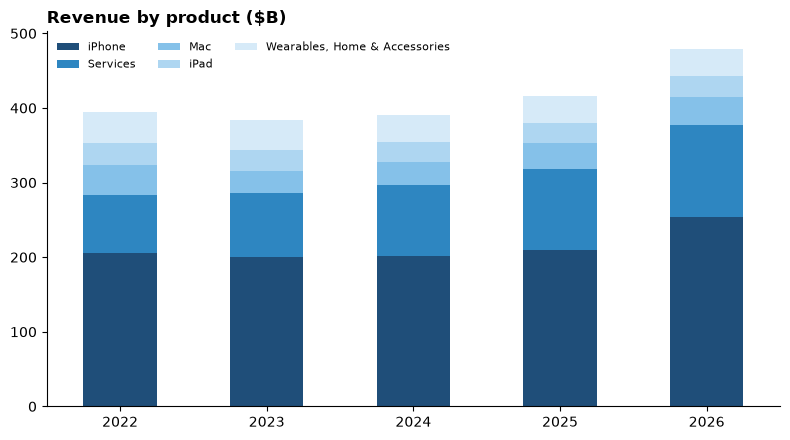

In [9]:
# Chart 3: Revenue mix
mix = products.pivot(index="fiscal_year", columns="product", values="revenue")
mix = mix[["iPhone", "Services", "Mac", "iPad", "Wearables, Home & Accessories"]] / 1000
mix.index = mix.index.astype(str)
mix.plot(kind="bar", stacked=True, figsize=(8, 4.5),
         color=["#1f4e79", "#2e86c1", "#85c1e9", "#aed6f1", "#d6eaf8"], rot=0)
plt.title("Revenue by product ($B)", loc="left", fontweight="bold")
plt.legend(frameon=False, fontsize=8, ncol=3); plt.xlabel("")
plt.tight_layout(); plt.savefig("../images/revenue_mix.png", dpi=150); plt.show()

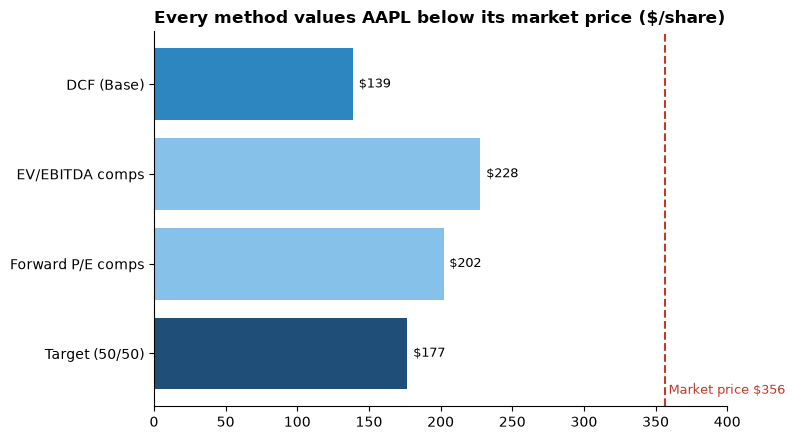

In [10]:
# Chart 4: Valuation summary vs market price
labels = ["DCF (Base)", "EV/EBITDA comps", "Forward P/E comps", "Target (50/50)"]
values = [dcf_value, price_ev_ebitda, price_pe, target_price]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(labels, values, color=["#2e86c1", "#85c1e9", "#85c1e9", "#1f4e79"])
ax.axvline(share_price, color="#c0392b", linestyle="--")
ax.text(share_price, 3.45, f" Market price ${share_price:.0f}", color="#c0392b", fontsize=9)
for i, v in enumerate(values):
    ax.text(v + 4, i, f"${v:.0f}", va="center", fontsize=9)
ax.set_xlim(0, 400); ax.invert_yaxis()
ax.set_title("Every method values AAPL below its market price ($/share)", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("../images/valuation_summary.png", dpi=150); plt.show()

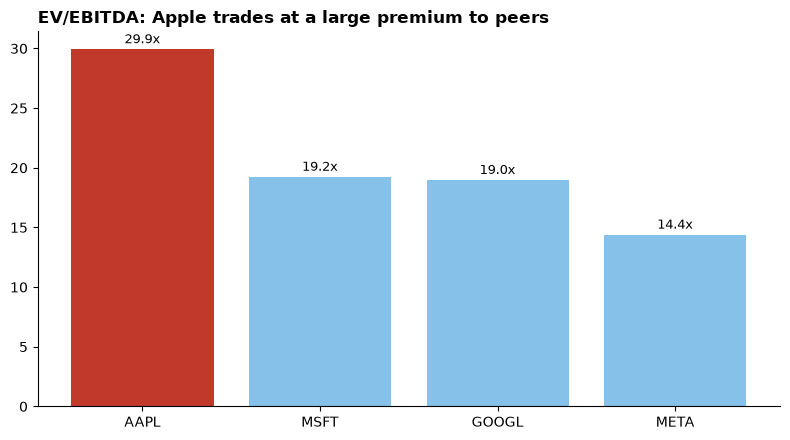

In [11]:
# Chart 5: Peer multiples
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#c0392b" if t == "AAPL" else "#85c1e9" for t in peers["ticker"]]
ax.bar(peers["ticker"], peers["ev_ebitda"], color=colors)
for x, v in zip(peers["ticker"], peers["ev_ebitda"]):
    ax.text(x, v + 0.5, f"{v:.1f}x", ha="center", fontsize=9)
ax.set_title("EV/EBITDA: Apple trades at a large premium to peers", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("../images/peer_ev_ebitda.png", dpi=150); plt.show()